# Laboratorium 1 — Obraz jako dane; od neuronu do klasyfikatora obrazów

**Cel:** zbudować pierwszy klasyfikator obrazów. Zobaczymy, jak obraz staje się tensorem, czym jest neuron i MLP, oraz jak wytrenować sieć rozpoznającą kategorie obrazów.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

W Google Colab większość bibliotek jest już dostępna; komórka poniżej gwarantuje właściwe wersje.

In [1]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

W Colab: **Runtime → Change runtime type → GPU** przyspiesza trening.

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


## 1. Teaser — gotowy model rozpoznaje obiekt na zdjęciu

Zanim cokolwiek wytrenujemy, uruchommy **gotową** sieć (ResNet-18 nauczoną na ImageNet), która rozpoznaje 1000 kategorii obiektów. To pokazuje cel przedmiotu w jednej komórce.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


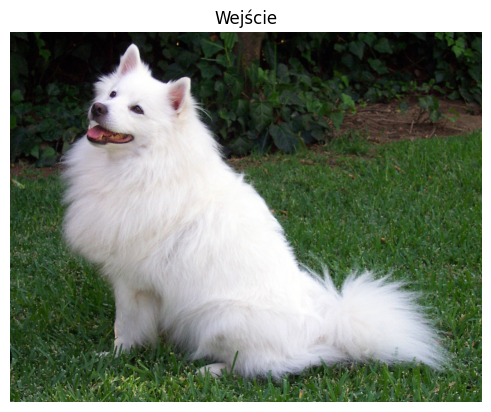

Top-5 predykcji:
  Samoyed                 88.5%
  Arctic fox               4.6%
  white wolf               4.4%
  Pomeranian               0.6%
  Great Pyrenees           0.5%


In [3]:
import urllib.request
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights

# przykładowe zdjęcie (w Colab pobiera się z sieci)
url = "https://github.com/pytorch/hub/raw/master/images/dog.jpg"
urllib.request.urlretrieve(url, "sample.jpg")
img = Image.open("sample.jpg").convert("RGB")

weights = ResNet18_Weights.DEFAULT
model_pre = resnet18(weights=weights).to(device).eval()
preprocess = weights.transforms()          # właściwy preprocessing dla tego modelu
categories = weights.meta["categories"]     # 1000 nazw klas ImageNet

x = preprocess(img).unsqueeze(0).to(device)  # [1, 3, H, W]
with torch.no_grad():
    probs = model_pre(x).softmax(1)[0]
top5 = probs.topk(5)

plt.imshow(img); plt.axis("off"); plt.title("Wejście"); plt.show()
print("Top-5 predykcji:")
for p, i in zip(top5.values, top5.indices):
    print(f"  {categories[i]:22s} {p.item()*100:5.1f}%")

## 2. Dane: FashionMNIST

Do własnego klasyfikatora użyjemy **FashionMNIST** — 70 000 obrazów odzieży 28×28 w skali szarości, 10 klas. `transforms` zamienia obraz na tensor i normalizuje wartości pikseli.

In [4]:
mean, std = 0.2860, 0.3530  # statystyki FashionMNIST
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.8MB/s]

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000


## 3. Obraz jako dane (tensor)

Pojedynczy obraz po transformacji to tensor `[1, 28, 28]` (kanał, wysokość, szerokość). Podejrzyjmy kształt, zakres wartości i kilka przykładów.

Kształt tensora obrazu: (1, 28, 28)
min/max wartości: -0.81 2.023
Etykieta: 9 -> Ankle boot


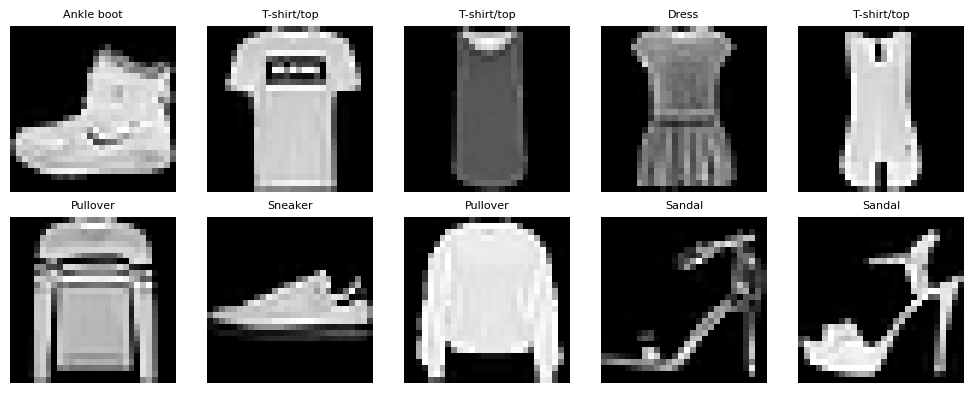

In [5]:
img_t, label = train_ds[0]
print("Kształt tensora obrazu:", tuple(img_t.shape))   # [1, 28, 28]
print("min/max wartości:", round(img_t.min().item(), 3), round(img_t.max().item(), 3))
print("Etykieta:", label, "->", classes[label])

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, range(10)):
    im, lb = train_ds[idx]
    ax.imshow(im.squeeze()*std + mean, cmap="gray")  # denormalizacja do podglądu
    ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model: perceptron wielowarstwowy (MLP)

`Flatten` spłaszcza obraz `[1,28,28]` do wektora 784, dalej idą warstwy gęste z ReLU, a ostatnia zwraca 10 logitów (po jednym na klasę).

In [6]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        # dynamiczne budowanie warstw na podstawie tupli 'hidden'
        layers = [nn.Flatten()]
        prev_dim = in_dim
        for h_dim in hidden:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(nn.ReLU())
            prev_dim = h_dim
        layers.append(nn.Linear(prev_dim, n_classes))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Test czy działa dla modelu bazowego
model = MLP().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Liczba parametrów:", n_params)

xb, yb = next(iter(train_dl))
print("Wejście:", tuple(xb.shape), "-> wyjście:", tuple(model(xb.to(device)).shape))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Liczba parametrów: 235146
Wejście: (128, 1, 28, 28) -> wyjście: (128, 10)


## 5. Trening

Pętla: **forward → strata (entropia krzyżowa) → backward → krok Adam**, powtórzona przez kilka epok. Po każdej epoce liczymy stratę i accuracy na zbiorze testowym.

In [7]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 8
hist = {"train_loss": [], "test_loss": [], "test_acc": []}
for epoch in range(1, EPOCHS+1):
    model.train()
    run_loss = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        run_loss += loss.item()*yb.numel()
    train_loss = run_loss/len(train_ds)
    test_loss, test_acc = evaluate(model, test_dl)
    hist["train_loss"].append(train_loss)
    hist["test_loss"].append(test_loss)
    hist["test_acc"].append(test_acc)
    print(f"Epoka {epoch:2d} | strata trening {train_loss:.3f} | test {test_loss:.3f} | accuracy {test_acc*100:.2f}%")

Epoka  1 | strata trening 0.484 | test 0.406 | accuracy 85.17%
Epoka  2 | strata trening 0.348 | test 0.389 | accuracy 85.85%
Epoka  3 | strata trening 0.312 | test 0.347 | accuracy 87.55%
Epoka  4 | strata trening 0.288 | test 0.345 | accuracy 87.56%
Epoka  5 | strata trening 0.268 | test 0.346 | accuracy 87.85%
Epoka  6 | strata trening 0.250 | test 0.331 | accuracy 88.42%
Epoka  7 | strata trening 0.234 | test 0.329 | accuracy 88.35%
Epoka  8 | strata trening 0.223 | test 0.324 | accuracy 88.69%


In [9]:
# Definicja 3 wariantów
variants = {
    "V1: Mala (128,)": (128,),
    "V2: Bazowa (256, 128)": (256, 128),
    "V3: Duza (512, 256, 128)": (512, 256, 128)
}

results_table = []
EPOCHS = 8

print("--- Trenowanie wariantów ---")
for name, hidden_dims in variants.items():
    # Tworzymy nowy model dla każdego wariantu
    current_model = MLP(hidden=hidden_dims).to(device)
    n_params = sum(p.numel() for p in current_model.parameters())

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(current_model.parameters(), lr=1e-3)

    for epoch in range(1, EPOCHS+1):
        current_model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(current_model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()*yb.numel()

    # Ewaluacja na zbiorze testowym
    test_loss, test_acc = evaluate(current_model, test_dl)
    results_table.append([name, n_params, f"{test_acc*100:.2f}%"])
    print(f"Zakonczono: {name} | Accuracy: {test_acc*100:.2f}%")

# Wyświetlenie tabeli wyników
print("\n| Architektura | Liczba parametrów | Accuracy (Test) |")
print("|---|---|---|")
for row in results_table:
    print(f"| {row[0]} | {row[1]} | {row[2]} |")

--- Trenowanie wariantów ---
Zakonczono: V1: Mala (128,) | Accuracy: 87.87%
Zakonczono: V2: Bazowa (256, 128) | Accuracy: 89.12%
Zakonczono: V3: Duza (512, 256, 128) | Accuracy: 88.19%

| Architektura | Liczba parametrów | Accuracy (Test) |
|---|---|---|
| V1: Mala (128,) | 101770 | 87.87% |
| V2: Bazowa (256, 128) | 235146 | 89.12% |
| V3: Duza (512, 256, 128) | 567434 | 88.19% |


## 6. Ewaluacja: krzywe i podgląd predykcji

Krzywe straty pokazują przebieg uczenia; siatka predykcji — gdzie model trafia (zielony) i myli się (czerwony); w nawiasie prawdziwa klasa.

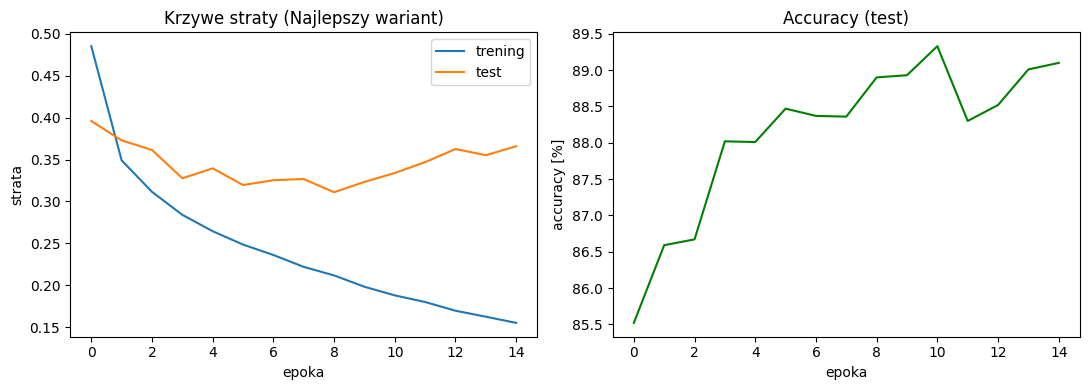

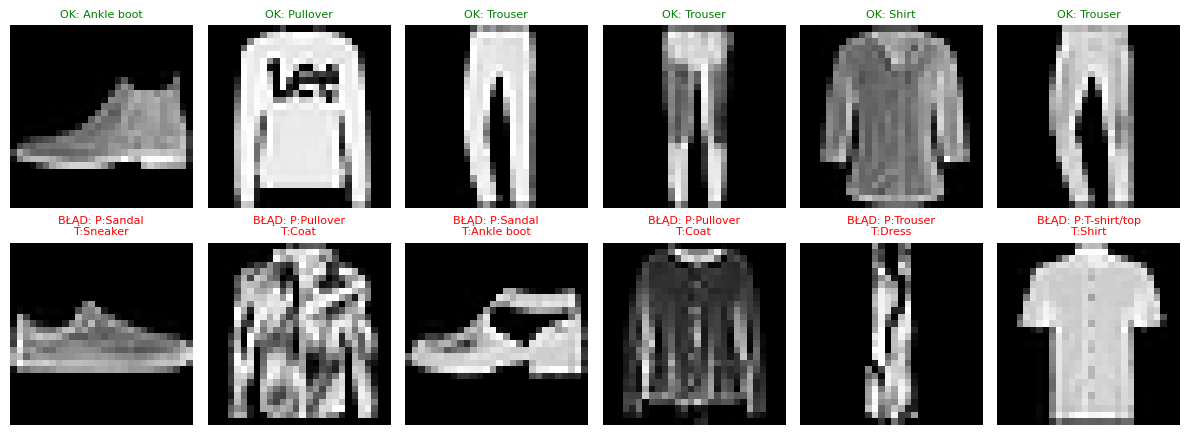

In [11]:
best_model = MLP(hidden=(256, 128)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(best_model.parameters(), lr=1e-3)

# Zwiększamy liczbę epok do 15, żeby lepiej zobaczyć przeuczenie (spadek na teście)
EPOCHS_BEST = 15
hist = {"train_loss": [], "test_loss": [], "test_acc": []}

for epoch in range(1, EPOCHS_BEST+1):
    best_model.train()
    run_loss = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(best_model(xb), yb)
        loss.backward()
        optimizer.step()
        run_loss += loss.item()*yb.numel()
    train_loss = run_loss/len(train_ds)
    test_loss, test_acc = evaluate(best_model, test_dl)
    hist["train_loss"].append(train_loss)
    hist["test_loss"].append(test_loss)
    hist["test_acc"].append(test_acc)

# Rysowanie krzywych
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(hist["train_loss"], label="trening")
ax1.plot(hist["test_loss"], label="test")
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(); ax1.set_title("Krzywe straty (Najlepszy wariant)")
ax2.plot([a*100 for a in hist["test_acc"]], color="green")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.set_title("Accuracy (test)")
plt.tight_layout(); plt.show()

# 2. SIATKA PREDYKCJI: TRAFNE I BŁĘDNE
best_model.eval()
xb, yb = next(iter(test_dl))
with torch.no_grad():
    pred = best_model(xb.to(device)).argmax(1).cpu()

# Znajdujemy indeksy poprawnych i błędnych predykcji w tym batchu
correct_idx = (pred == yb).nonzero().squeeze(-1)
wrong_idx = (pred != yb).nonzero().squeeze(-1)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))

# Trafne (bierzemy pierwsze 6 z listy poprawnych)
for ax, i in zip(axes[0], range(6)):
    idx = correct_idx[i].item()
    ax.imshow(xb[idx].squeeze()*std + mean, cmap="gray")
    ax.set_title(f"OK: {classes[pred[idx]]}", fontsize=8, color="green")
    ax.axis("off")

# Błędne (bierzemy pierwsze 6 z listy błędnych)
for ax, i in zip(axes[1], range(6)):
    idx = wrong_idx[i].item()
    ax.imshow(xb[idx].squeeze()*std + mean, cmap="gray")
    # co przewidział (P) i co było prawdą (T)
    ax.set_title(f"BŁĄD: P:{classes[pred[idx]]}\nT:{classes[yb[idx]]}", fontsize=8, color="red")
    ax.axis("off")

plt.tight_layout(); plt.show()

## 7. Podsumowanie

- Obraz to tensor `[C, H, W]`; paczka `[N, C, H, W]`.
- MLP spłaszcza obraz i klasyfikuje go warstwami gęstymi z ReLU.
- Trening = forward → strata (CE) → backward → krok optymalizatora, przez wiele epok.
- MLP ignoruje strukturę przestrzenną obrazu — dlatego od **zajęć 4** przechodzimy na sieci splotowe (CNN).

**Zadanie na sprawozdanie:** zobacz `zadanie.md`.

---
*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*